## 0. Описание задачи

По данным о клиенте (возраст, пол, уровень образования, семейное положение, кредитный лимит, история платежей, длительность задолженностей и сумма выплат) необходимо определить, допустит ли он дефолт в следующем месяце (т.е. не произведёт платёж вовремя). Это задача бинарной классификации:

Класс 0: клиент оплатит вовремя

Класс 1: клиент не оплатит (дефолт)

Количество записей в датасете 30 000, количество признаков - 23, количество классов - 2



In [5]:
# Ячейка 1: импорты
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score, RocCurveDisplay)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Чтение данных

Чтение производится из репозитория на GitHub

In [18]:
url = 'https://raw.githubusercontent.com/CodeLine-26/ML/refs/heads/main/UCI_Credit_Card.csv'
data_raw = pd.read_csv(url)
# если ссылка не работает - загрузить файл в Colab и указать путь:
# data_raw = pd.read_csv('listings.csv.gz')
print(data_raw.shape)

(30000, 25)


In [19]:
#Далее демонстрируются 15 наудачу выбранных строк датасета
data_raw.sample(15)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
9949,9950,30000.0,2,2,2,25,1,3,2,2,...,17018.0,16608.0,18020.0,0.0,0.0,2000.0,0.0,2000.0,0.0,0
23067,23068,440000.0,2,1,2,33,0,0,0,0,...,139178.0,123627.0,48175.0,5666.0,5802.0,3577.0,2955.0,12000.0,1025.0,0
12786,12787,340000.0,2,1,1,38,-1,-1,0,0,...,82049.0,57667.0,80767.0,41951.0,50000.0,30000.0,5000.0,80767.0,10000.0,0
14309,14310,50000.0,2,1,2,22,-1,0,0,0,...,18587.0,20316.0,18271.0,2000.0,2000.0,1000.0,2000.0,1000.0,2950.0,1
21342,21343,150000.0,1,2,1,57,2,2,2,2,...,15744.0,16582.0,17166.0,1600.0,1300.0,0.0,1100.0,1000.0,1000.0,1
10642,10643,230000.0,1,1,1,48,0,0,0,0,...,105508.0,108101.0,110094.0,7000.0,6607.0,3773.0,4290.0,4164.0,2000.0,0
5426,5427,50000.0,2,2,1,49,-1,-1,-1,-1,...,198.0,1198.0,11198.0,9115.0,1198.0,198.0,1198.0,11198.0,29358.0,1
12358,12359,200000.0,2,1,1,41,-1,-1,-1,-1,...,5529.0,10332.0,6894.0,8756.0,3539.0,5529.0,10332.0,6894.0,3188.0,0
877,878,280000.0,2,2,2,27,-1,-1,-1,-1,...,3058.0,3158.0,9530.0,5174.0,1078.0,3058.0,3158.0,9530.0,0.0,0
13398,13399,100000.0,1,3,2,50,0,0,0,0,...,69166.0,53270.0,-1465.0,4200.0,2785.0,2291.0,1965.0,1465.0,62121.0,0


# Разбиваем данные на обучающую и тестовую выборки

Определяем столбец с целевой переменной, разбиваем на обучающую (80%) и тестовую(20%) выборки

In [20]:
target_col = 'default.payment.next.month'

X = data_raw.drop(columns=[target_col])
y = data_raw[target_col]

X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:",X_test.shape)
print(f"Распределение классов в обучающей выборке:\n{y_train.value_counts(normalize=True)}")

Размер обучающей выборки: (24000, 24)
Размер тестовой выборки: (6000, 24)
Распределение классов в обучающей выборке:
default.payment.next.month
0    0.778792
1    0.221208
Name: proportion, dtype: float64


# Выведем основную статистику числовых признаков

Следует отметить, что пол (SEX), образование (EDUCATION), семейное положение (MARRIAGE) - категориальные признаки, хоть и выражены численными значениями. Это будет учтено далее.

Признак PAY_i содержит значение -k, если выплата в этом месяце была произведена за k месяцев задолженности, значение n, если задержка выплаты составляет n месяцев. k,n - натуральные.

In [21]:
print(data_raw.describe())

                 ID       LIMIT_BAL           SEX     EDUCATION      MARRIAGE  \
count  30000.000000    30000.000000  30000.000000  30000.000000  30000.000000   
mean   15000.500000   167484.322667      1.603733      1.853133      1.551867   
std     8660.398374   129747.661567      0.489129      0.790349      0.521970   
min        1.000000    10000.000000      1.000000      0.000000      0.000000   
25%     7500.750000    50000.000000      1.000000      1.000000      1.000000   
50%    15000.500000   140000.000000      2.000000      2.000000      2.000000   
75%    22500.250000   240000.000000      2.000000      2.000000      2.000000   
max    30000.000000  1000000.000000      2.000000      6.000000      3.000000   

                AGE         PAY_0         PAY_2         PAY_3         PAY_4  \
count  30000.000000  30000.000000  30000.000000  30000.000000  30000.000000   
mean      35.485500     -0.016700     -0.133767     -0.166200     -0.220667   
std        9.217904      1.123802

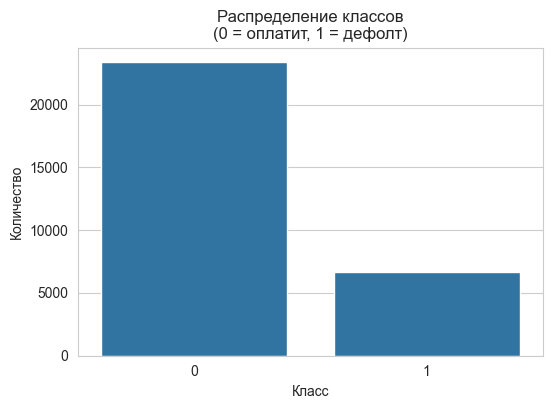

Доля классов:
0 (оплатит): 77.88%
1 (дефолт): 22.12%


In [22]:

plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=data_raw)
plt.title('Распределение классов\n(0 = оплатит, 1 = дефолт)')
plt.xlabel('Класс')
plt.ylabel('Количество')
plt.show()

class_ratio = data_raw[target_col].value_counts(normalize=True)
print(f"Доля классов:\n0 (оплатит): {class_ratio[0]:.2%}\n1 (дефолт): {class_ratio[1]:.2%}")

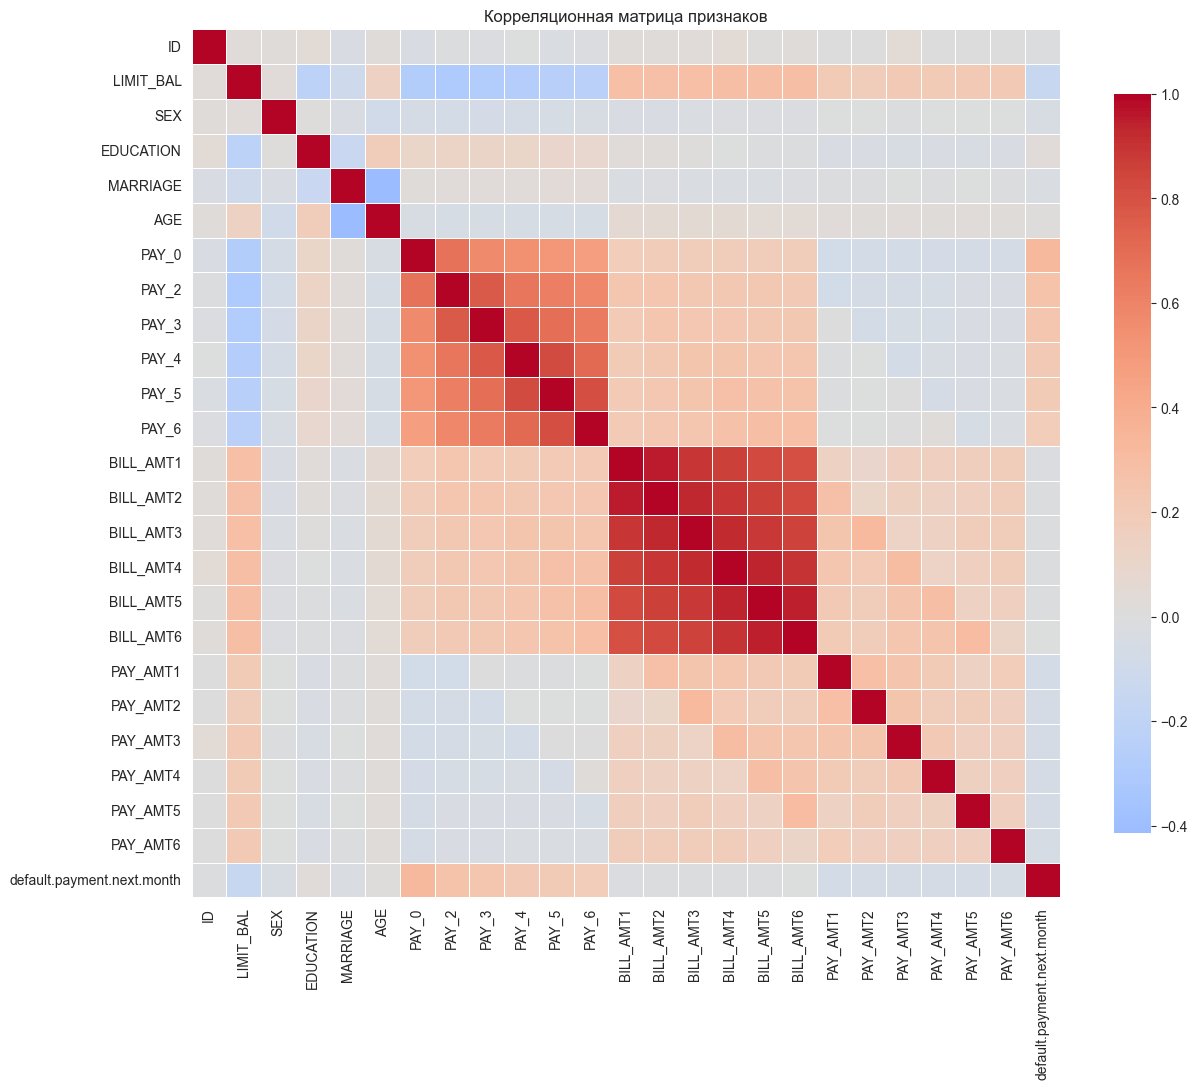


Топ-5 признаков по корреляции с целевой переменной:
PAY_0    0.324794
PAY_2    0.263551
PAY_3    0.235253
PAY_4    0.216614
PAY_5    0.204149
Name: default.payment.next.month, dtype: float64


In [23]:
#Построение корелляционной матрицы признаков и нахождение наиболее кореллирующих признаков

corr_matrix = data_raw.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    annot=False,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title('Корреляционная матрица признаков')
plt.show()

target_corr = corr_matrix[target_col].abs().sort_values(ascending=False)
print("\nТоп-5 признаков по корреляции с целевой переменной:")
print(target_corr[1:6])

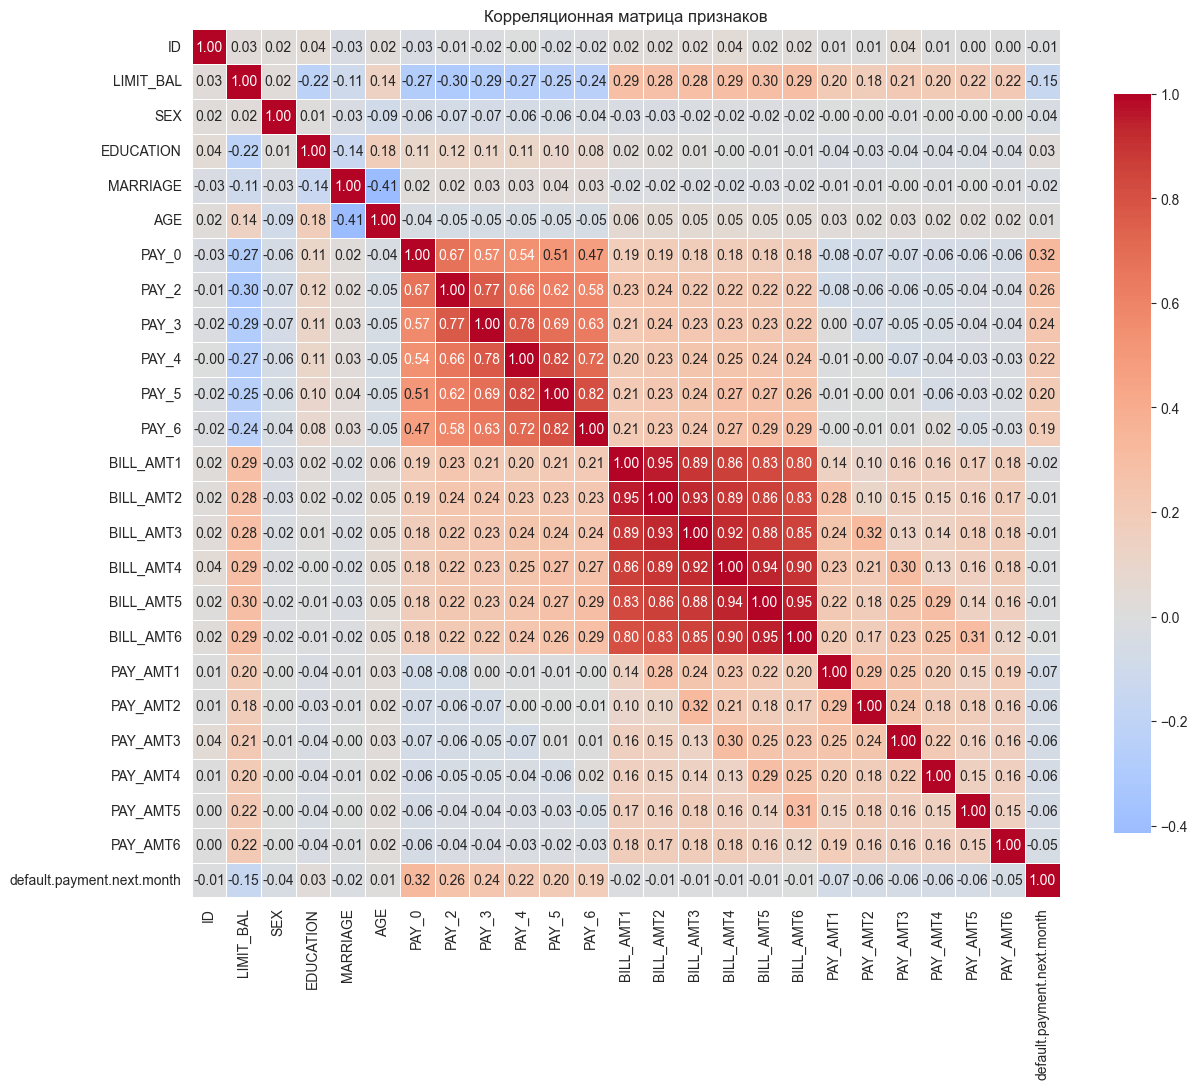

In [31]:

corr_matrix = data_raw.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title('Корреляционная матрица признаков')
plt.show()

Больше всего с целевой переменной кореллирует информация о своевременности выплат. Причём именно выплата в первый (нулевой) месяц кореллирует более заметно. Неужели здесь "встречают по одёжке"??? Спорный вопрос. Значение на пересечении соответстующих строки и столбца сравнительно мало.

Отметим ещё один интересный нюанс: размеры выплат сильно кореллируют друг с другом. Особенно это заметно для выплат в подряд идущие месяцы. Следовательно, в среднем человек, обладающий стабильным доходом (исправно платящий по счетам), тратит схожие суммы каждый месяц. Трудно провести дальнейший анализ в условиях отсутствия данных об условии кредитования

# Обращение с пропущенными значениями

In [32]:
missing = data_raw.isnull().sum()
if missing.sum() == 0:
    print("Пропущенных значений нет.")
else:
    print("Найдено", missing.sum(), "пропущенных значений")

Пропущенных значений нет.


# Обработка категориальных признаков

В описании к датасету уточняется, что некоторые различные значения категориальных признаков следует принять равными. В частности это относится к признакам семейного положения и образования. Обработку их начнём с исследования на наличие этих фиктивно-различных признаков:

In [33]:

values_of_interest = [4, 5, 6]
counts = data_raw['EDUCATION'].value_counts().reindex(values_of_interest, fill_value=0)
print (counts)

EDUCATION
4    123
5    280
6     51
Name: count, dtype: int64


In [34]:
# Затем объединим их:
def fix_categories(df):
    
    df = df.copy()
    df['EDUCATION'] = df['EDUCATION'].replace([0, 5, 6], 4)
    df['MARRIAGE'] = df['MARRIAGE'].replace(0, 3)
    return df

X_train = fix_categories(X_train)
X_test = fix_categories(X_test)

#  Проведём нормализацию

Нормализация обязательна для kNN, так как признаки в разных масштабах:

LIMIT_BAL: от 10 000 до 1 000 000

AGE: 21–79

PAY_0: -2 до 8

Выбран RobustScaler, т.к. StandardScaler сдвигает среднее (центрирует относительно 0), изменяет масштаб. MinMaxScaler же прижимает основную часть данных к одному из краёв отрезка [0, 1]. Оба преобразования не подходят (признаки в датасете смещены вправо). RobustScaler, использующий в преобразовании медиану и межкваркильный размах, устойчив к выбросам и наиболее подходит для этой задачи

In [35]:
scaler = sklearn.preprocessing.RobustScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Запуск классификатора (метод k ближайших соседей)

На начальном этапе выберем k произвольным (k=5)

In [36]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=21, n_jobs=-1)
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",21
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",-1


In [37]:
#Получение предсказаний модели на обучающей и тестовой выборках
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

# Подсчёт ошибок

С помощью средств библиотеки sklearn.metrics выведем метрики:

Accuracy — доля правильных предсказаний среди всех объектов.

Precision — доля верно предсказанных положительных классов среди всех, кого модель назвала «положительными».

Recall — доля найденных положительных объектов среди всех реальных «положительных».

F1-score — гармоническое среднее между precision и recall.

Выведем также матрицы рассогласования

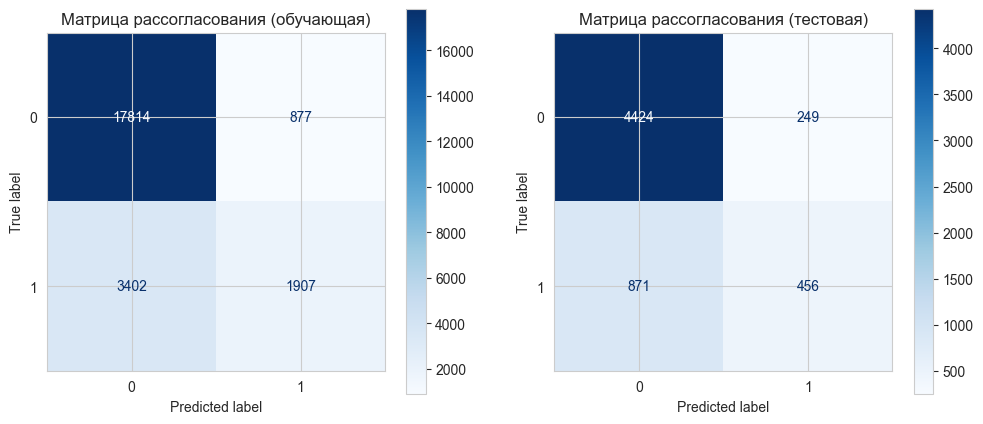


=== Обучающая выборка ===
Accuracy : 0.8217
Precision: 0.6850
Recall   : 0.3592
F1-score : 0.4713

=== Тестовая выборка ===
Accuracy : 0.8133
Precision: 0.6468
Recall   : 0.3436
F1-score : 0.4488


In [38]:
def print_metrics(y_true, y_pred, label):
    acc = sklearn.metrics.accuracy_score(y_true, y_pred)
    prec = sklearn.metrics.precision_score(y_true, y_pred)
    rec = sklearn.metrics.recall_score(y_true, y_pred)
    f1 = sklearn.metrics.f1_score(y_true, y_pred)
    print(f"\n=== {label} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sklearn.metrics.ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=ax[0], cmap='Blues')
ax[0].set_title('Матрица рассогласования (обучающая)')

sklearn.metrics.ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=ax[1], cmap='Blues')
ax[1].set_title('Матрица рассогласования (тестовая)')

plt.show()

print_metrics(y_train, y_train_pred, "Обучающая выборка")
print_metrics(y_test, y_test_pred, "Тестовая выборка")

На первый взгляд может показаться, что результат замечательный - точность около 81% на тестовой выборке - хороший результат. Но правильно ли использовать эту метрику в задачах с несбаллансированными классами?

В датасете:

~78% клиентов не допускают дефолта (класс 0)

~22% клиентов допускают дефолт (класс 1) Теперь представьте, которая всегда предсказывает 0:

Она будет права в 78% случаев → accuracy = 0.78 Но при этом ни один дефолт не будет обнаружен → recall = 0, F1 = 0

А значение F1-score весьма скромно - не дотягивает до 45%. Попробуем улучшить модель выбором оптимального значения гиперпараметра k (кол-во ближайших соседей).

Далее показана процедура подбора оптимального k на отрезке [3, 35] по нечётным значениям.


=== Финальная модель (оптимальное k = 33 ) ===

=== Обучающая выборка (лучшая модель) ===
Accuracy : 0.8200
Precision: 0.6818
Recall   : 0.3490
F1-score : 0.4617

=== Тестовая выборка (лучшая модель) ===
Accuracy : 0.8077
Precision: 0.6237
Recall   : 0.3286
F1-score : 0.4304


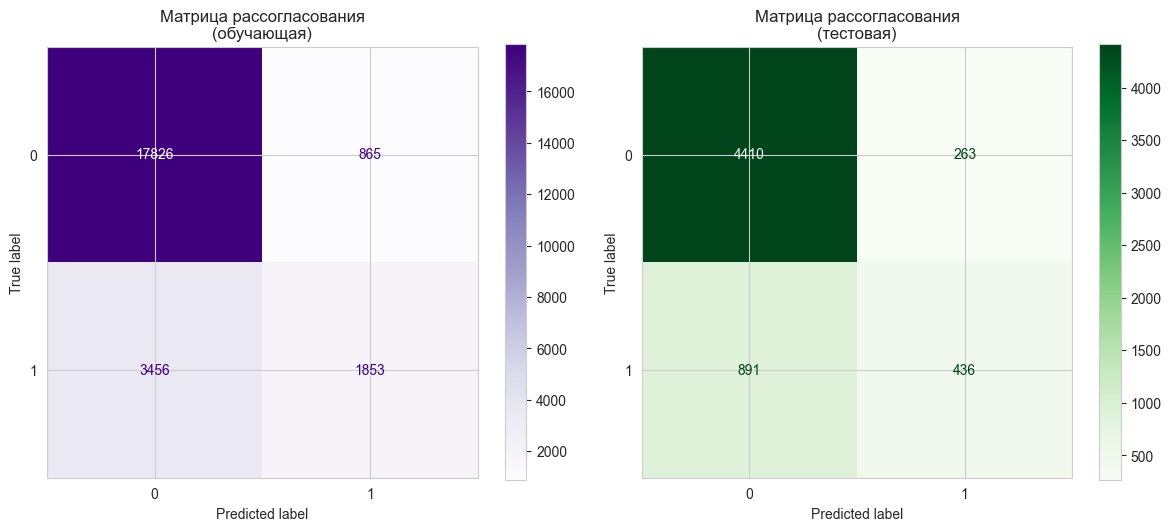

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay
param_grid = {'n_neighbors': list(range(3, 35, 2))}

knn_grid = sklearn.neighbors.KNeighborsClassifier(n_jobs=-1)
grid_search = sklearn.model_selection.GridSearchCV(
    knn_grid,
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

# лучшая модель, уже переобученная на всей обучающей выборке
best_knn = grid_search.best_estimator_

y_train_pred_best = best_knn.predict(X_train_scaled)
y_test_pred_best = best_knn.predict(X_test_scaled)

print("\n=== Финальная модель (оптимальное k =", grid_search.best_params_['n_neighbors'], ") ===")
print_metrics(y_train, y_train_pred_best, "Обучающая выборка (лучшая модель)")
print_metrics(y_test, y_test_pred_best, "Тестовая выборка (лучшая модель)")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_best, ax=ax[0], cmap='Purples')
ax[0].set_title('Матрица рассогласования\n(обучающая)')

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_best, ax=ax[1], cmap='Greens')
ax[1].set_title('Матрица рассогласования\n(тестовая)')

plt.tight_layout()
plt.show()

За кадром остались попытки улучшить точность посредством выбора 5-7 наиболее важных признаков, исключение экстремумов BILL_AMT и PAY_AMT с помощью лог-трансформации. Это не дало больших результатов. Вместо этого приведём пример использования алгоритма Random Forest:


=== Random Forest ===

=== Обучающая выборка ===
Accuracy : 0.7965
Precision: 0.5331
Recall   : 0.6461
F1-score : 0.5842

=== Тестовая выборка ===
Accuracy : 0.7752
Precision: 0.4931
Recall   : 0.5901
F1-score : 0.5372


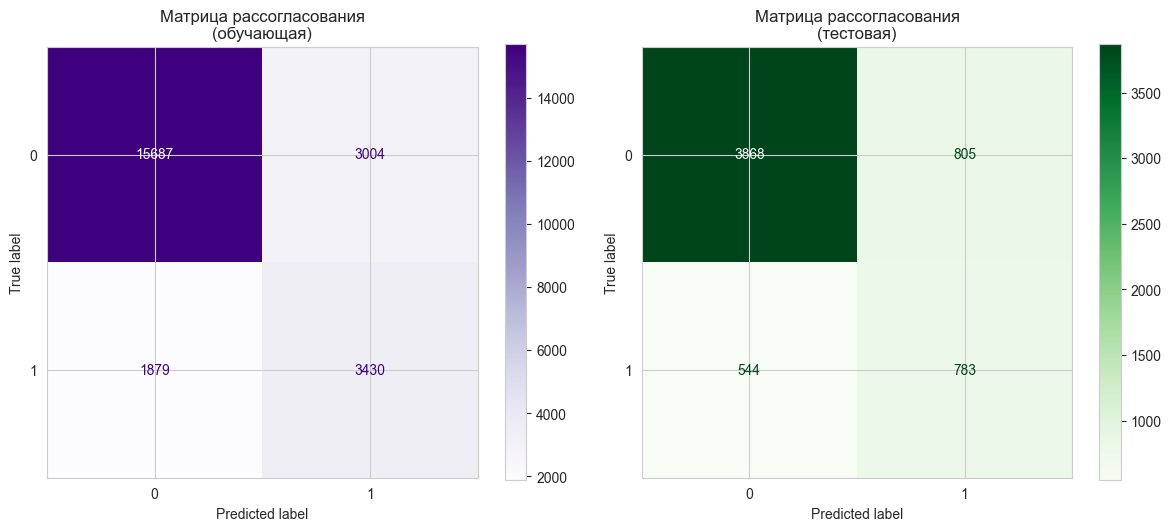

In [45]:
import pandas as pd
import sklearn.model_selection
import sklearn.ensemble
from sklearn.metrics import f1_score, classification_report

url = 'https://raw.githubusercontent.com/ARBUZNIJ/ML_2025/refs/heads/master/UCI_Credit_Card.csv'

df = pd.read_csv(url)

df = df.rename(columns={'default.payment.next.month': 'target'})
df = df.drop('ID', axis=1)

pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
pay_cols = [col for col in pay_cols if col in df.columns]

for col in pay_cols:
    df[f'{col}_late'] = (df[col] > 0).astype(int)

df = df.drop(pay_cols, axis=1)

df['EDUCATION'] = df['EDUCATION'].replace([0, 5, 6], 4)
df['MARRIAGE'] = df['MARRIAGE'].replace(0, 3)

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

rf = sklearn.ensemble.RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

print(f"\n=== Random Forest ===")

print_metrics(y_train, y_train_pred, "Обучающая выборка")
print_metrics(y_test, y_test_pred, "Тестовая выборка")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=ax[0], cmap='Purples')
ax[0].set_title('Матрица рассогласования\n(обучающая)')

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=ax[1], cmap='Greens')
ax[1].set_title('Матрица рассогласования\n(тестовая)')

plt.tight_layout()
plt.show()

# Выводы

По выбранному датасету были обучены модели с использованием алгоритма kNN и Random Forest. Модель, обученная с использованием Random Forest демонстрирует более высокие показатели метрики F1-score. Действительно, этот алгоритм более приспособлен к наличию выбросов и не требует масштабирования данных. Random Forest находит чуть больше всех дефолтов, чем kNN, но при этом меньше предсказанных дефолтов оказываются реальными. Random Forest чуть более безопасен для использования в финансовой сфере (не так страшен неверно предсказанный дефолт клиента, как не предсказанный). Стоит отметить, что корелляционная матрица содержит невысокие значения корелляций параметров. Это негативно отражается на предсказаниях. Следует попробовать уточнить датасет параметрами, полученными на основе уже существующих или иными, не рассмотренными ранее.